# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data

## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team wants to market a limited edition San Francisco Cable Car model to existing California customers with a high credit limit (over 25,000).

*Hint*: Make sure creditLimit is numeric.

In [2]:
# creditLimit is stored as TEXT in this database, so CAST it to a number before comparing.
# Comparing it as text would sort '105000.00' below '25000' alphabetically and give wrong results.
q2 = pd.read_sql("""
SELECT customerNumber, customerName, contactFirstName, contactLastName, city, state, creditLimit
FROM customers
WHERE state = 'CA'
  AND country = 'USA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY CAST(creditLimit AS REAL) DESC
""", conn)
q2

,customerNumber,customerName,contactFirstName,contactLastName,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,San Rafael,CA,210500.00
1,239,Collectable Mini Designs Co.,Valarie,Thompson,San Diego,CA,105000.00
2,321,Corporate Gift Ideas Co.,Julie,Brown,San Francisco,CA,105000.00
3,205,Toys4GrownUps.com,Julie,Young,Pasadena,CA,90700.00
4,161,Technics Stores Inc.,Juri,Hashimoto,Burlingame,CA,84600.00
5,450,The Sharp Gifts Warehouse,Sue,Frick,San Jose,CA,77600.00
6,129,Mini Wheels Co.,Julie,Murphy,San Francisco,CA,64600.00
7,487,Signal Collectibles Ltd.,Sue,Taylor,Brisbane,CA,60300.00
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,Los Angeles,CA,57700.00
9,475,West Coast Collectables Co.,Steve,Thompson,Burbank,CA,55400.00


### Step 3: International Collectable Campaign

Find international (non-US) customers who have "Collect" in their name.

In [3]:
q3 = pd.read_sql("""
SELECT customerNumber, customerName, country
FROM customers
WHERE country <> 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName
""", conn)
q3

,customerNumber,customerName,country
0,471,"Australian Collectables, Ltd",Australia
1,114,"Australian Collectors, Co.",Australia
2,382,Salzburg Collectables,Austria
3,260,"Royal Canadian Collectables, Ltd.",Canada
4,227,Heintze Collectables,Denmark
5,353,Reims Collectables,France
6,415,"Bavarian Collectables Imports, Co.",Germany
7,409,Stuttgart Collectable Exchange,Germany
8,211,"King Kong Collectables, Co.",Hong Kong
9,189,"Clover Collections, Co.",Ireland


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Answer

The WHERE clause is a two-part checklist that every customer has to pass before they appear in the results, and the word AND means a customer must pass **both** parts.

1. **`country <> 'USA'`** means "country is not equal to USA". This removes every American customer, so only international customers are left.
2. **`customerName LIKE '%Collect%'`** means "the name contains the letters *Collect* somewhere". The `%` signs are wildcards that stand for "any text", so `%Collect%` matches the word at the start, middle or end of a name. That catches *Collectables*, *Collectors* and *Collections*, whereas an exact match (`=`) would only find a customer named literally "Collect". SQLite's `LIKE` also ignores upper/lower case, so we don't miss names because of capitalization.

Because of the first rule, look-alikes such as "Cambridge Collectables Co." or "Signal Collectibles Ltd." (US customers) are correctly excluded. The result is 15 international customers, and I checked it against a plain "name contains Collect" search (23 matches) to confirm that the 8 removed ones were all US-based.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team wants the average credit limit of customers by state to inform inventory allocation, credit policy and marketing.

In [4]:
# Again CAST creditLimit to a number so AVG works on real numeric values
q4 = pd.read_sql("""
SELECT state,
       COUNT(*) AS num_customers,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC
""", conn)
q4

,state,num_customers,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


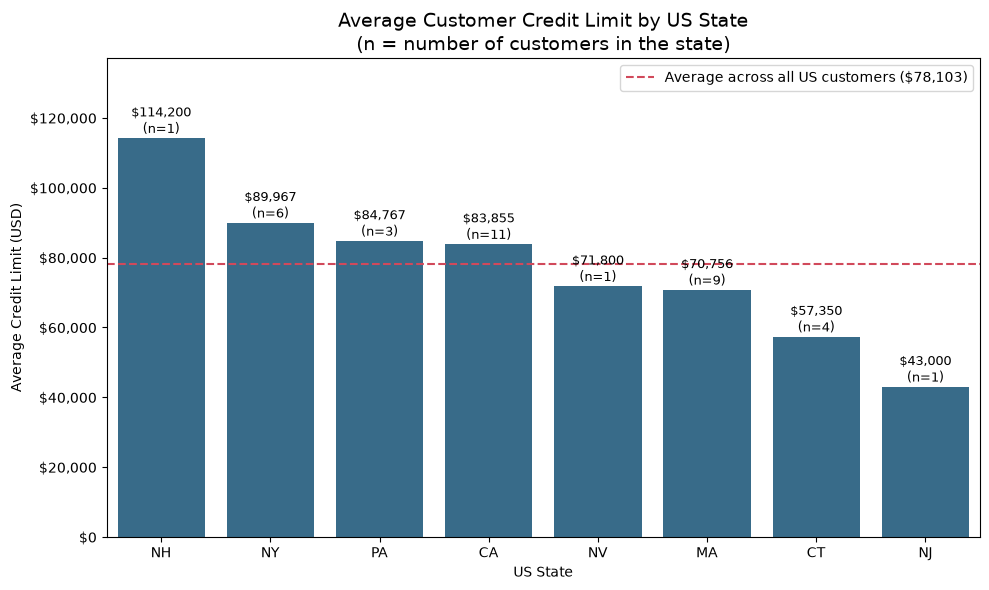

In [5]:
# Bar chart: one bar per state (a categorical comparison of a single numeric measure), sorted high to low
overall_avg = pd.read_sql("SELECT AVG(CAST(creditLimit AS REAL)) AS a FROM customers WHERE country = 'USA'", conn).a[0]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=q4, x='state', y='avg_credit_limit', color='#2a6f97', ax=ax)
ax.axhline(overall_avg, color='#d1495b', linestyle='--', label=f'Average across all US customers (${overall_avg:,.0f})')
for i, row in q4.iterrows():
    ax.text(i, row.avg_credit_limit + 1500, f"${row.avg_credit_limit:,.0f}\n(n={row.num_customers})", ha='center', fontsize=9)
ax.set_title('Average Customer Credit Limit by US State\n(n = number of customers in the state)', fontsize=14)
ax.set_xlabel('US State')
ax.set_ylabel('Average Credit Limit (USD)')
ax.set_ylim(0, q4.avg_credit_limit.max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax.legend()
plt.tight_layout()
plt.show()

**Takeaway:** NH, NV and NJ have only one customer each, so their averages are single credit limits rather than real state-level trends. Among states with a meaningful number of customers, NY (about \$90K), PA and CA have the highest average limits, while CT and NJ sit well below the roughly \$80K overall average.

### Step 5: Top Customers - Visual Required
Determine the top 10 customers by total amount of payments made, returning the customer name.

In [6]:
q5 = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       SUM(CAST(p.amount AS REAL)) AS total_payments
FROM customers c
JOIN payments p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10
""", conn)
q5

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


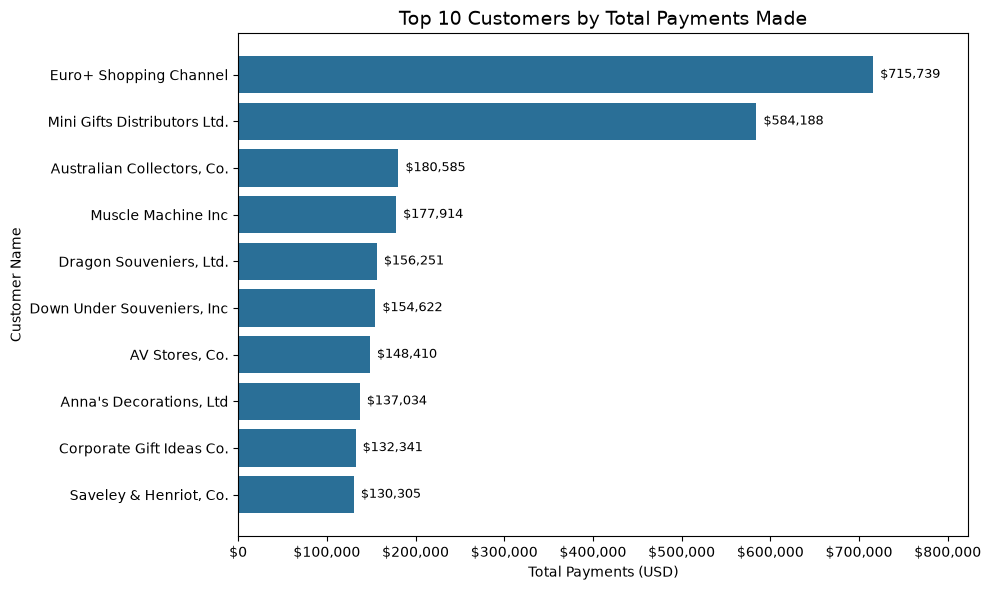

In [7]:
# Horizontal bar chart: long customer names are easier to read on the y-axis, and bars show rank order clearly
plot5 = q5.sort_values('total_payments')
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot5.customerName, plot5.total_payments, color='#2a6f97')
for b in bars:
    ax.text(b.get_width() + 8000, b.get_y() + b.get_height()/2, f"${b.get_width():,.0f}", va='center', fontsize=9)
ax.set_title('Top 10 Customers by Total Payments Made', fontsize=14)
ax.set_xlabel('Total Payments (USD)')
ax.set_ylabel('Customer Name')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax.set_xlim(0, plot5.total_payments.max() * 1.15)
plt.tight_layout()
plt.show()

**Takeaway:** Euro+ Shopping Channel and Mini Gifts Distributors are far ahead of everyone else (each is more than 3x the third-ranked customer), so the 10-year thank-you outreach could reasonably treat those two as a separate tier.

### Step 6: Top Customer + Product Quantities
For each customer, return any product they purchased 10 or more units of, sorted ascending by the total amount purchased.

In [8]:
q6 = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       p.productCode,
       p.productName,
       SUM(od.quantityOrdered) AS total_quantity
FROM customers c
JOIN orders o        ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber    = od.orderNumber
JOIN products p      ON od.productCode   = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(od.quantityOrdered) >= 10
ORDER BY total_quantity ASC
""", conn)
q6

,customerNumber,customerName,productCode,productName,total_quantity
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required
For each product line, return the total quantity ordered and the total number of products.

In [9]:
# COUNT(DISTINCT ...) is needed: joining to orderdetails repeats each product once per order line,
# so a plain COUNT would count products many times over.
q7 = pd.read_sql("""
SELECT pl.productLine,
       COUNT(DISTINCT p.productCode) AS number_of_products,
       SUM(od.quantityOrdered)       AS total_quantity_ordered
FROM productlines pl
JOIN products p      ON pl.productLine = p.productLine
JOIN orderdetails od ON p.productCode  = od.productCode
GROUP BY pl.productLine
ORDER BY total_quantity_ordered DESC
""", conn)
q7

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


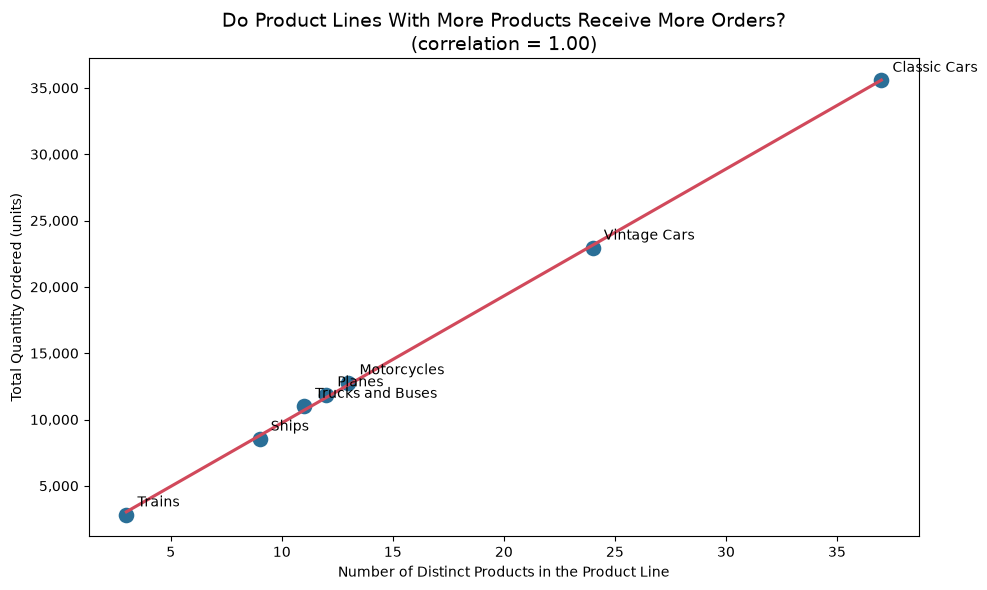

In [10]:
# Scatter plot: both variables are numeric and we want to see whether they move together
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=q7, x='number_of_products', y='total_quantity_ordered', s=150, color='#2a6f97', ax=ax)
sns.regplot(data=q7, x='number_of_products', y='total_quantity_ordered', scatter=False, color='#d1495b', ci=None, ax=ax)
for _, r in q7.iterrows():
    ax.annotate(r.productLine, (r.number_of_products, r.total_quantity_ordered),
                textcoords='offset points', xytext=(8, 6), fontsize=10)
corr = q7.number_of_products.corr(q7.total_quantity_ordered)
ax.set_title(f'Do Product Lines With More Products Receive More Orders?\n(correlation = {corr:.2f})', fontsize=14)
ax.set_xlabel('Number of Distinct Products in the Product Line')
ax.set_ylabel('Total Quantity Ordered (units)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Answer

I used a **scatter plot**, because the question is "do product lines with more products get more orders?", which is a question about the relationship between two numbers. Each dot is one product line, placed according to how many products it has (left to right) and how many units customers ordered (bottom to top). If bigger catalogs led to more orders, the dots would climb from the lower left to the upper right. A bar chart would show each number separately but would make that relationship much harder to see at a glance. I added labels so each dot can be recognized and a trend line to show the overall direction.

The dots do rise steadily and the correlation is very close to 1 (about 1.00). **Product lines with more products have clearly received more orders**: Classic Cars (37 products) leads with about 35,600 units, and Trains (3 products) is lowest with about 2,800. Per product the demand is actually fairly similar across lines (roughly 940 to 1,000 units each), so the extra volume comes mostly from having more products to sell, not from each product being more popular. One caution is that this is only 7 product lines, and the data cannot tell us whether big lines sell more because they have more products or whether the company added more products to lines that were already popular.

### Step 8: Remote Offices
Provide data about employees who work in any office that has fewer than 5 total employees, including job and supervisor information.

In [11]:
q8 = pd.read_sql("""
SELECT e.employeeNumber,
       e.firstName,
       e.lastName,
       e.jobTitle,
       e.officeCode,
       o.city AS office_city,
       e.reportsTo AS supervisorNumber,
       s.firstName AS supervisorFirstName,
       s.lastName  AS supervisorLastName
FROM employees e
JOIN offices o ON e.officeCode = o.officeCode
LEFT JOIN employees s ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY e.officeCode, e.lastName
""", conn)
q8

,employeeNumber,firstName,lastName,jobTitle,officeCode,office_city,supervisorNumber,supervisorFirstName,supervisorLastName
0,1188,Julie,Firrelli,Sales Rep,2,Boston,1143,Anthony,Bow
1,1216,Steve,Patterson,Sales Rep,2,Boston,1143,Anthony,Bow
2,1286,Foon Yue,Tseng,Sales Rep,3,NYC,1143,Anthony,Bow
3,1323,George,Vanauf,Sales Rep,3,NYC,1143,Anthony,Bow
4,1625,Yoshimi,Kato,Sales Rep,5,Tokyo,1621,Mami,Nishi
5,1621,Mami,Nishi,Sales Rep,5,Tokyo,1056,Mary,Patterson
6,1611,Andy,Fixter,Sales Rep,6,Sydney,1088,William,Patterson
7,1619,Tom,King,Sales Rep,6,Sydney,1088,William,Patterson
8,1612,Peter,Marsh,Sales Rep,6,Sydney,1088,William,Patterson
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,1056,Mary,Patterson


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Answer

The request has two layers: first find which *offices* are small, then list the *employees* in those offices. The condition "fewer than 5 employees" is an aggregate over a whole office (it needs a count of all its employees), but the final output needs one row per individual employee. If I put `COUNT(*) < 5` directly in the main query, `GROUP BY` would collapse the employees into one row per office and I would lose the employee-level detail.

So I wrote the subquery to do only the office-level work: `SELECT officeCode FROM employees GROUP BY officeCode HAVING COUNT(*) < 5` returns the list of office codes with fewer than 5 employees (2, 3, 5, 6 and 7). `HAVING` is used instead of `WHERE` because it filters on the aggregate `COUNT(*)` after grouping. The main query then keeps its normal employee-level rows and uses `WHERE e.officeCode IN (subquery)` to keep only employees in those offices. This approach is dynamic, since if headcount changes the query still returns the right offices without hard-coding office codes. I also joined `offices` for the city name and self-joined `employees` (as `s`) on `reportsTo = employeeNumber` to bring in the supervisor's name; it is a LEFT JOIN so an employee with no supervisor (the president) would not be dropped.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Part 2 Analysis

**Focus:** Which kinds of movies do audiences rate highly and engage with most (votes)? I focus on genre and runtime, since these are the levers a studio or streaming service controls when deciding what to make or acquire.

#### 1. Scope of the data and what is out of range

In [14]:
# Movies per start_year: confirms the stated 2010-2019 range and shows the out-of-range records
years = pd.read_sql("""
SELECT start_year, COUNT(*) AS num_movies
FROM movie_basics
GROUP BY start_year
ORDER BY start_year
""", conn4)
print(years.to_string(index=False))
print('\nRows after 2019 (to exclude):', years[years.start_year > 2019].num_movies.sum())

 start_year  num_movies
       2010       11849
       2011       12900
       2012       13787
       2013       14709
       2014       15589
       2015       16243
       2016       17272
       2017       17504
       2018       16849
       2019        8379
       2020         937
       2021          83
       2022          32
       2023           5
       2024           2
       2025           1
       2026           1
       2027           1
       2115           1

Rows after 2019 (to exclude): 1063


#### 2. Load the analysis set: 2010-2019 movies with a rating, genre and runtime (nulls excluded, nothing filled in)

In [15]:
movies = pd.read_sql("""
SELECT b.movie_id, b.primary_title, b.start_year, b.runtime_minutes, b.genres,
       r.averagerating, r.numvotes
FROM movie_basics b
JOIN movie_ratings r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.genres IS NOT NULL
  AND b.runtime_minutes IS NOT NULL
""", conn4)
print(movies.shape)
movies.describe().round(2)

(65720, 7)


,start_year,runtime_minutes,averagerating,numvotes
count,65720.00,65720.00,65720.00,65720.00
mean,2014.26,94.73,6.32,3954.67
std,2.60,209.38,1.46,32088.23
min,2010.00,3.00,1.00,5.00
25%,2012.00,81.00,5.50,16.00
50%,2014.00,91.00,6.50,62.00
75%,2016.00,104.00,7.30,352.00
max,2019.00,51420.00,10.00,1841066.00


#### 3. Initial exploration: genre, runtime and year

In [16]:
# genres is a comma-separated string (e.g. 'Action,Crime,Drama'), so split it into one row per genre.
# A movie with 3 genres counts once in each of them.
exploded = movies.assign(genre=movies.genres.str.split(',')).explode('genre')

genre_all = (exploded.groupby('genre')
             .agg(num_movies=('movie_id', 'count'),
                  avg_rating=('averagerating', 'mean'),
                  median_votes=('numvotes', 'median'))
             .sort_values('num_movies', ascending=False).round(2))
genre_all.head(12)

,num_movies,avg_rating,median_votes
genre,,,
Drama,28394,6.39,85.0
Documentary,16423,7.32,21.0
Comedy,15514,6.01,118.5
Thriller,7583,5.59,165.0
Horror,6917,4.93,103.0
Action,6297,5.78,242.0
Romance,5976,6.15,149.0
Crime,4338,6.11,203.5
Biography,3693,7.17,41.0


In [17]:
# Runtime buckets vs rating and engagement
movies['runtime_bucket'] = pd.cut(movies.runtime_minutes, [0, 60, 90, 120, 150, 100000],
                                  labels=['<=60 min', '61-90', '91-120', '121-150', '150+ min'])
runtime_summary = (movies.groupby('runtime_bucket', observed=True)
                   .agg(num_movies=('movie_id', 'count'),
                        avg_rating=('averagerating', 'mean'),
                        median_votes=('numvotes', 'median')).round(2))
display(runtime_summary)

print('\nSpearman correlations:')
print(movies[['runtime_minutes', 'averagerating', 'numvotes']].corr(method='spearman').round(2))

print('\nAverage rating by release year:')
print(movies.groupby('start_year').averagerating.mean().round(2).to_string())

,num_movies,avg_rating,median_votes
runtime_bucket,,,
<=60 min,4397,7.12,12.0
61-90,28096,6.23,40.0
91-120,26682,6.25,125.0
121-150,5222,6.42,206.0
150+ min,1323,6.69,228.0



Spearman correlations:
                 runtime_minutes  averagerating  numvotes
runtime_minutes             1.00          -0.07      0.35
averagerating              -0.07           1.00     -0.25
numvotes                    0.35          -0.25      1.00

Average rating by release year:
start_year
2010    6.27
2011    6.29
2012    6.29
2013    6.29
2014    6.32
2015    6.27
2016    6.33
2017    6.36
2018    6.38
2019    6.65


Observations so far:
- Documentary, Biography, History, Sport and Music titles earn the **highest average ratings**, while Horror (about 4.9), Sci-Fi and Thriller are lowest. 
- Many of the high-rated genres have **very low vote counts** (median 21 votes for Documentary), which means those ratings are based on small, probably self-selected audiences and are not reliable. I therefore require at least 1,000 votes in the genre comparison below.
- Longer movies are rated slightly higher and get far more votes (median votes 12 for movies of 60 minutes or less vs about 229 for 150+ minutes).

#### 4. Genre comparison with a reliability filter (at least 1,000 votes, at least 100 movies per genre)

In [18]:
reliable = exploded[exploded.numvotes >= 1000]
genre_stats = (reliable.groupby('genre')
               .agg(num_movies=('movie_id', 'count'),
                    avg_rating=('averagerating', 'mean'),
                    median_votes=('numvotes', 'median'))
               .query('num_movies >= 100')
               .sort_values('avg_rating', ascending=False).round(2))
genre_stats

,num_movies,avg_rating,median_votes
genre,,,
Documentary,741,7.27,2259.0
Biography,701,6.96,4559.0
Sport,196,6.93,2753.5
History,387,6.89,3590.0
Music,283,6.75,3637.0
War,163,6.72,3907.0
Animation,376,6.68,5289.5
Drama,5045,6.49,3789.0
Romance,1349,6.34,3564.0


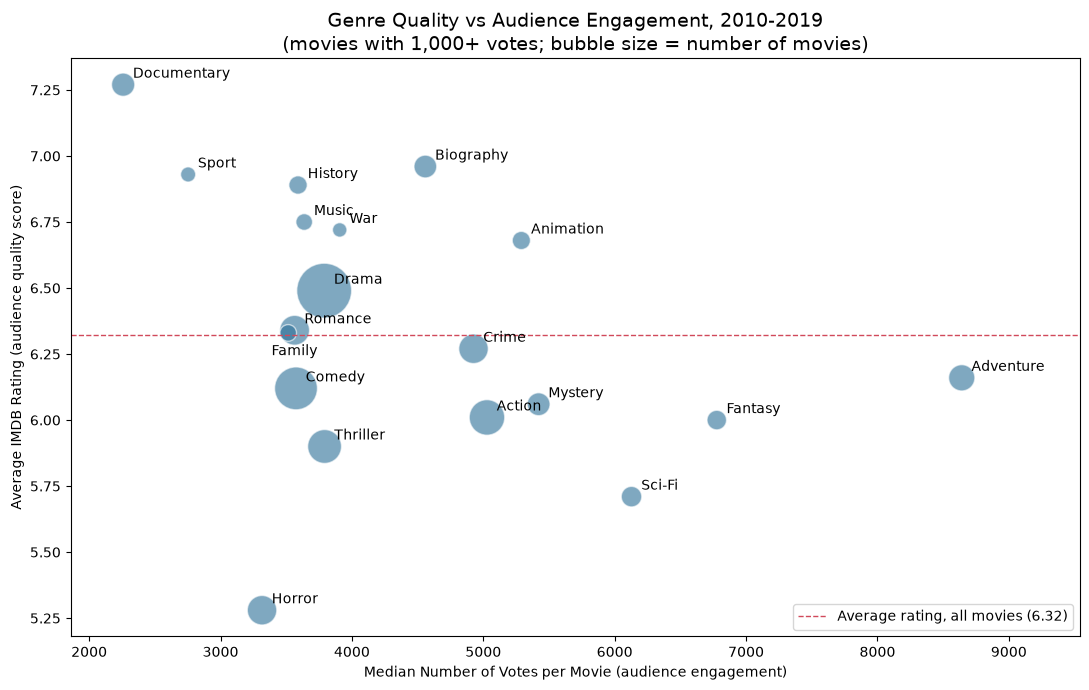

In [19]:
# Scatter: audience quality (avg rating) vs. audience engagement (median votes) for each genre
fig, ax = plt.subplots(figsize=(11, 7))
sizes = genre_stats.num_movies / genre_stats.num_movies.max() * 1500 + 60
ax.scatter(genre_stats.median_votes, genre_stats.avg_rating, s=sizes, alpha=0.6, color='#2a6f97', edgecolor='white')
for g, r in genre_stats.iterrows():
    offset = (-12, -16) if g == 'Family' else (7, 5)   # keep the Family / Romance labels from overlapping
    ax.annotate(g, (r.median_votes, r.avg_rating), textcoords='offset points', xytext=offset, fontsize=10)
ax.axhline(movies.averagerating.mean(), color='#d1495b', linestyle='--', linewidth=1,
           label=f'Average rating, all movies ({movies.averagerating.mean():.2f})')
ax.set_xlim(genre_stats.median_votes.min() - 400, genre_stats.median_votes.max() + 900)
ax.set_title('Genre Quality vs Audience Engagement, 2010-2019\n(movies with 1,000+ votes; bubble size = number of movies)', fontsize=14)
ax.set_xlabel('Median Number of Votes per Movie (audience engagement)')
ax.set_ylabel('Average IMDB Rating (audience quality score)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('genre_quality_vs_engagement.png', dpi=200)
plt.show()

### Deliverable 2: Business Question

**Which genres should a studio or streaming service prioritize for new films: those that combine high audience ratings with high engagement, or high-volume genres such as Drama and Comedy, and does a longer runtime help?**

This stems from the pattern above: after removing low-vote titles, Documentary, Biography, Animation and Drama still earn above-average ratings. Adventure, Fantasy, Sci-Fi and Mystery attract the most votes per movie (a sign of mass audience interest) but rate below the roughly 6.3 overall average, and Horror is both the lowest rated and among the lowest for engagement. A deeper analysis would join in `principals`/`directors` to see whether the director's track record or the cast explains the differences, and would split by release year to see whether the trends are stable over the decade.

### Deliverable 3: Potential Data Cleaning Tasks



In [20]:
# Quantify the data quality issues found during exploration
basics = pd.read_sql("SELECT * FROM movie_basics", conn4)
n = len(basics)
issues = {
    'Total movies in movie_basics': n,
    'Start year after 2019 (out of scope, incl. year 2115)': int((basics.start_year > 2019).sum()),
    'Missing runtime_minutes': int(basics.runtime_minutes.isna().sum()),
    'Missing genres': int(basics.genres.isna().sum()),
    'Movies with a rating row (rest have no rating)': pd.read_sql("SELECT COUNT(*) c FROM movie_ratings", conn4).c[0],
    'Runtime under 10 min or over 600 min (implausible outliers)': int(((basics.runtime_minutes < 10) | (basics.runtime_minutes > 600)).sum()),
    'Multi-genre values stored in one text field': int(basics.genres.str.contains(',', na=False).sum()),
    'primary_title differs from original_title': int((basics.primary_title != basics.original_title).sum()),
    'Rated movies with fewer than 100 votes': pd.read_sql("SELECT COUNT(*) c FROM movie_ratings WHERE numvotes < 100", conn4).c[0],
}
pd.Series(issues, name='count').to_frame()

,count
Total movies in movie_basics,146144
"Start year after 2019 (out of scope, incl. year 2115)",1063
Missing runtime_minutes,31739
Missing genres,5408
Movies with a rating row (rest have no rating),73856
Runtime under 10 min or over 600 min (implausible outliers),1204
Multi-genre values stored in one text field,59378
primary_title differs from original_title,14504
Rated movies with fewer than 100 votes,45103


**Cleaning task list**

1. **Filter out-of-range years:** remove movies with `start_year` after 2019 (including future/invalid years such as 2027 and 2115).
2. **Null handling:** drop (do not fill) rows with missing `runtime_minutes` (about 22% of movies) and missing `genres`; about half of all movies also have no row in `movie_ratings`, so an inner join silently drops them.
3. **Split multi-valued genres:** `genres` holds comma-separated lists, which should be normalized into one row per movie-genre pair (or a separate genre table) so genre can be grouped correctly.
4. **Handle runtime outliers:** values range from 1 to 51,420 minutes, so set sensible bounds (for example 40 to 300 minutes for feature films) and consider separating shorts.
5. **Reliability threshold on ratings:** many ratings rest on very few votes, so apply a minimum vote count (this analysis used 1,000).
6. **Standardize types and text:** `runtime_minutes`, `birth_year`, `death_year` are stored as floats (should be integers); check for inconsistent capitalization, whitespace and encoding in titles and names.
7. **Title consistency:** `primary_title` and `original_title` differ for about 14,500 movies (translations); decide which to use and standardize for matching.
8. **Check for duplicate records** in the link tables (`directors`, `writers`, `principals`, `known_for`) before joining them, since duplicated rows would inflate counts.